importation des bibliotheques

In [1]:
import numpy as np

chargement du dataset

In [2]:
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",",
                  names=True, dtype=None, encoding="utf-8")

extraction des colonnes

In [3]:
dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]

NOMS_MOIS = np.array(["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
                      "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])


la différence entre le tableau d et tmax par exemple est la dimension le tableau d est un tableau à plsuieurs dimensions contrairement à tmax qui est un tableau à une dimension une autre différence intervient dans le type de données le tableau d contient plusieurs types de données contrairement tmax

Affichez la forme, le nombre de dimensions et le type de tmax, mois et dates.

In [ ]:
#forme 
print(f" forme de tmax : {tmax.shape} \n forme de mois : {mois.shape} \n forme de date : {dates.shape} \n")
#dimension
print(f" dimension de tmax : {tmax.ndim} \n dimension de mois : {mois.ndim} \n dimension de date : {dates.ndim} \n")
#le types
print(f" type de tmax : {tmax.dtype} \n type de mois : {mois.dtype} \n type de date : {dates.dtype}")


 forme de tmax : (365,) 
 forme de mois : (365,) 
 forme de date : (365,) 

 dimension de tmax : 1 
 dimension de mois : 1 
 dimension de date : 1 

 type de tmax : float64 
 type de mois : int64 
 type de date : <U10


Affichez la température maximale la plus basse et la plus haute de l'année, puis la moyenne annuelle de tmax et de tmin, arrondies à deux décimales.

In [13]:
print(f" temperature maximale la plus haute : {tmax.max()}")
print(f" temperature maximale la plus basse : {tmin.min()}")


 temperature maximale la plus haute : 34.1
 temperature maximale la plus basse : 16.1


In [40]:
#les températures maximales de la première semaine de janvier 
print(f"temperatures maximales de la premiere semaine de janvier : {tmax[0:7]} \n")
#les températures maximales des 10 derniers jours de l'année
print(f"temperatures maximales des 10 derniers jours de l'année : {tmax[-10:]} \n")
#toutes les données du 15 mars (date, tmax, tmin, pluie) 
masque_15_mars = (mois == 3) & (jour == 15)
print("Données du 15 mars (date, tmax, tmin, pluie) :",
      dates[masque_15_mars], tmax[masque_15_mars], tmin[masque_15_mars], pluie[masque_15_mars], "\n")
#les températures maximales d'un jour sur sept à partir du 1er janvier
print(f"temperature max tous les septs jours : {tmax[::7]}")



temperatures maximales de la premiere semaine de janvier : [27.1 26.7 26.  26.  27.9 27.1 24.6] 

temperatures maximales des 10 derniers jours de l'année : [26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ] 

Données du 15 mars (date, tmax, tmin, pluie) : ['2025-03-15'] [26.4] [19.1] [0.] 

temperature max tous les septs jours : [27.1 26.1 24.8 25.  23.5 24.5 25.6 27.2 28.6 25.9 25.2 27.4 26.8 26.3
 25.  27.4 29.5 28.7 26.5 26.4 25.7 27.8 25.5 30.8 30.4 28.3 28.8 28.9
 27.5 30.1 29.2 30.9 30.1 29.3 28.7 28.2 30.8 32.8 30.  33.1 29.3 31.6
 30.7 32.2 28.5 28.7 28.8 26.4 25.3 27.1 28.6 26.1 27. ]


Avec argmax et argmin, trouvez la date de la journée la plus chaude (selon tmax) et celle de la nuit la plus fraîche (selon tmin).

In [47]:
index_temperature_max = np.argmax(tmax)#on recupere l'idex du jour le plus chaud
print(f"Le jour le plus chaud était le : {dates[index_temperature_max]}")

index_temperature_min = np.argmin(tmin)#on recupere l'index de la nuit la plus fraiche
print(f"Le jour le plus frais était le : {dates[index_temperature_min]}")


Le jour le plus chaud était le : 2025-09-18
Le jour le plus frais était le : 2025-02-07


Partie 3 — Statistiques mensuelles 

3.1 Avec un masque sur mois, calculez la moyenne de tmax pour le seul mois d'août.

In [38]:
print(f"Moyenne de tmax en août : {tmax[mois == 8].mean():.2f}")

Moyenne de tmax en août : 30.22


3.2 Expliquez pourquoi on écrit mois - 1, puis affichez chaque moyenne à côté du nom de son mois.

In [43]:
nb_jours = np.bincount(mois - 1)                 # jours par mois
somme    = np.bincount(mois - 1, weights=tmax)   # somme de tmax par mois
moy_tmax = somme / nb_jours
print(np.column_stack((NOMS_MOIS, moy_tmax)))


[['Jan' '25.29354838709678']
 ['Fév' '25.846428571428568']
 ['Mar' '26.35806451612903']
 ['Avr' '26.573333333333334']
 ['Mai' '26.63870967741935']
 ['Juin' '29.233333333333334']
 ['Juil' '28.467741935483875']
 ['Août' '30.216129032258063']
 ['Sep' '30.88']
 ['Oct' '31.19677419354839']
 ['Nov' '28.48333333333333']
 ['Déc' '26.86774193548387']]


3.3 Quel est le mois le plus chaud en moyenne ? Le plus frais ? Utilisez argmax, argmin et NOMS_MOIS.

In [48]:
index_temperature_max = np.argmax(moy_tmax)#on recupere l'index du mois le plus chaud
print(f"Le jour le plus chaud était le : {NOMS_MOIS[index_temperature_max]}")

index_temperature_min = np.argmin(moy_tmax)#on recupere l'index du mois le plus frais
print(f"Le jour le plus frais était le : {NOMS_MOIS[index_temperature_min]}")

Le jour le plus chaud était le : Oct
Le jour le plus frais était le : Jan


3.4 L'amplitude thermique d'un jour est tmax - tmin. Calculez-la pour chaque jour, puis son maximum et sa moyenne par mois. À quelle saison l'amplitude est-elle la plus faible ?

In [52]:
#amplitude pour chaque jour 
amplitude = tmax - tmin
#moyenne par mois
somme    = np.bincount(mois - 1, weights=amplitude)
amplitude_moy_mois = somme / nb_jours
print(f"amplitude moyenne par mois : \n {np.column_stack((NOMS_MOIS, amplitude_moy_mois))}")
#amplitude max par mois 
amplitude = tmax - tmin
debuts_mois = np.cumsum(nb_jours) - nb_jours
amp_max_mois = np.maximum.reduceat(amplitude, debuts_mois)
print(f" amplitude max par mois : \n {np.column_stack((NOMS_MOIS,amp_max_mois))}")

amplitude moyenne par mois : 
 [['Jan' '7.1']
 ['Fév' '7.971428571428572']
 ['Mar' '7.170967741935482']
 ['Avr' '6.8866666666666685']
 ['Mai' '5.851612903225806']
 ['Juin' '5.463333333333335']
 ['Juil' '4.325806451612904']
 ['Août' '4.680645161290322']
 ['Sep' '5.623333333333333']
 ['Oct' '6.193548387096774']
 ['Nov' '6.62']
 ['Déc' '7.225806451612903']]
 amplitude max par mois : 
 [['Jan' '8.7']
 ['Fév' '9.700000000000003']
 ['Mar' '8.2']
 ['Avr' '8.8']
 ['Mai' '7.199999999999999']
 ['Juin' '8.3']
 ['Juil' '6.699999999999999']
 ['Août' '6.200000000000003']
 ['Sep' '8.299999999999997']
 ['Oct' '8.3']
 ['Nov' '8.799999999999997']
 ['Déc' '8.5']]


3.5 Calculez le cumul de pluie par mois et le total annuel. Quel pourcentage du total tombe en août ? Combien de mois sont totalement secs ?

In [53]:
cumul_pluie = np.bincount(mois - 1, weights=pluie)
total_pluie = cumul_pluie.sum()

print(f"cumul de pluie par mois : \n {np.column_stack((NOMS_MOIS, cumul_pluie))}")
print(f"\nTotal annuel : {total_pluie:.1f}")
print(f"Part du total tombée en août : {cumul_pluie[7] / total_pluie * 100:.1f} %")
print("Nombre de mois totalement secs :", np.sum(cumul_pluie == 0))

cumul de pluie par mois : 
 [['Jan' '0.0']
 ['Fév' '0.0']
 ['Mar' '0.0']
 ['Avr' '0.0']
 ['Mai' '0.8']
 ['Juin' '13.5']
 ['Juil' '71.4']
 ['Août' '275.2']
 ['Sep' '70.3']
 ['Oct' '22.6']
 ['Nov' '9.4']
 ['Déc' '0.0']]

Total annuel : 463.2
Part du total tombée en août : 59.4 %
Nombre de mois totalement secs : 5


Partie 4 — Masques booléens


4.1 Combien de jours dépassent 30 °C sur l'année ? Calculez ensuite ce nombre pour chaque mois avec np.bincount en passant le masque comme poids.

In [54]:
chaud = tmax > 30
print("Jours > 30 °C sur l'année :", chaud.sum())

par_mois = np.bincount(mois - 1, weights=chaud.astype(int), minlength=12).astype(int)
print("\nJours > 30 °C par mois :")
print(np.column_stack((NOMS_MOIS, par_mois)))

Jours > 30 °C sur l'année : 82

Jours > 30 °C par mois :
[['Jan' '0']
 ['Fév' '0']
 ['Mar' '0']
 ['Avr' '0']
 ['Mai' '0']
 ['Juin' '12']
 ['Juil' '3']
 ['Août' '16']
 ['Sep' '21']
 ['Oct' '24']
 ['Nov' '6']
 ['Déc' '0']]


4.2 Comparez la moyenne de tmax des jours de pluie et des jours secs. Comment l'expliquez-vous ?

In [55]:
jours_pluie = pluie > 0
print(f"Moyenne de tmax les jours de pluie : {tmax[jours_pluie].mean():.2f} °C  ({jours_pluie.sum()} jours)")
print(f"Moyenne de tmax les jours secs     : {tmax[~jours_pluie].mean():.2f} °C  ({(~jours_pluie).sum()} jours)")

Moyenne de tmax les jours de pluie : 29.02 °C  (53 jours)
Moyenne de tmax les jours secs     : 27.84 °C  (312 jours)


Les jours pluvieux ont une `tmax` moyenne **plus élevée** que les jours secs

4.3 Combien de jours sont à la fois humides (humidité supérieure à 85 %) et venteux (vent supérieur à 15 km/h) ? Affichez leurs dates.

In [56]:
humide_venteux = (hum > 85) & (vent > 15)
print("Nombre de jours humides (> 85 %) et venteux (> 15 km/h) :", humide_venteux.sum())
print(dates[humide_venteux])

Nombre de jours humides (> 85 %) et venteux (> 15 km/h) : 11
['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


4.4 Créez une copie de tmax nommée tmax_ecretee dans laquelle toute valeur supérieure à 31 °C est remplacée par 31. Vérifiez que tmax n'a pas été modifié. Recommencez sans .copy() et expliquez ce qui se passe, puis rechargez les données avant de continuer.

In [57]:
# Avec .copy()
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31
print("Avec copy -> max de tmax_ecretee :", tmax_ecretee.max(), "| max de tmax :", tmax.max())

Avec copy -> max de tmax_ecretee : 31.0 | max de tmax : 34.1


In [58]:
# Sans .copy() : tmax_ecretee n'est qu'un autre nom pour le MÊME tableau
tmax_ecretee = tmax
tmax_ecretee[tmax_ecretee > 31] = 31
print("Sans copy -> max de tmax_ecretee :", tmax_ecretee.max(), "| max de tmax :", tmax.max())
print("Même objet ?", tmax_ecretee is tmax, "| partagent la mémoire ?", np.shares_memory(tmax, tmax_ecretee))

Sans copy -> max de tmax_ecretee : 31.0 | max de tmax : 31.0
Même objet ? True | partagent la mémoire ? True


Avec `.copy()`, `tmax_ecretee` est un **nouveau** tableau indépendant : écrêter la copie ne touche pas `tmax`.
Sans `.copy()`, l'affectation `tmax_ecretee = tmax` ne crée qu'une **seconde référence** vers le même tableau en mémoire :
modifier `tmax_ecretee` modifie aussi `tmax` (et même `d`, puisque `tmax` est une vue de `d["temp_max_c"]`). Les données d'origine sont alors perdues : on recharge le fichier.

In [59]:
# Rechargement des données d'origine
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",",
                  names=True, dtype=None, encoding="utf-8")
dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]
print("tmax rechargé -> max :", tmax.max(), "°C")

tmax rechargé -> max : 34.1 °C


4.5 Utilisez np.where pour créer un tableau de chaînes qui vaut "chaud" au-dessus de 29 °C, "doux" entre 26 et 29 °C, et "frais" en dessous. Comptez chaque catégorie avec np.unique(..., return_counts=True)."

In [60]:
categorie = np.where(tmax > 29, "chaud", np.where(tmax >= 26, "doux", "frais"))
valeurs, comptes = np.unique(categorie, return_counts=True)
print(np.column_stack((valeurs, comptes)))

[['chaud' '116']
 ['doux' '175']
 ['frais' '74']]


Partie 5 — Transformations et broadcasting

5.1 Convertissez tmax en degrés Fahrenheit (F = C × 9/5 + 32), sans boucle.

In [61]:
tmax_f = tmax * 9 / 5 + 32
print("Premières valeurs (°C) :", tmax[:5])
print("Premières valeurs (°F) :", tmax_f[:5])

Premières valeurs (°C) : [27.1 26.7 26.  26.  27.9]
Premières valeurs (°F) : [80.78 80.06 78.8  78.8  82.22]


5.2 Assemblez les cinq variables numériques dans une matrice de 365 lignes et 5 colonnes, puis affichez sa forme.

In [62]:
X = np.column_stack([tmax, tmin, hum, pluie, vent])
VARIABLES = np.array(["tmax", "tmin", "humidité", "pluie", "vent"])
print("Forme de X :", X.shape)

Forme de X : (365, 5)


5.3 Calculez la moyenne et l'écart-type de chaque variable avec axis=0. Quelle est la forme du résultat ? Que donnerait axis=1, et pourquoi n'a-t-il pas de sens ici ?

In [63]:
moy_col = X.mean(axis=0)
std_col = X.std(axis=0)
print("Forme du résultat :", moy_col.shape)
print("Moyennes :")
print(np.column_stack((VARIABLES, moy_col)))
print("\nÉcarts-types :")
print(np.column_stack((VARIABLES, std_col)))
print("\nForme avec axis=1 :", X.mean(axis=1).shape)

Forme du résultat : (5,)
Moyennes :
[['tmax' '28.013698630136986']
 ['tmin' '21.76712328767124']
 ['humidité' '74.7972602739726']
 ['pluie' '1.269041095890411']
 ['vent' '17.202739726027396']]

Écarts-types :
[['tmax' '2.4643938413059336']
 ['tmin' '2.9281933648685867']
 ['humidité' '8.127241062526792']
 ['pluie' '6.075411968529541']
 ['vent' '4.668459386333614']]

Forme avec axis=1 : (365,)


`axis=0` « écrase » l'axe des lignes (les jours) : on obtient une statistique **par colonne**, donc un tableau de forme `(5,)`.
`axis=1` donnerait une valeur par **jour** (forme `(365,)`), en mélangeant des grandeurs d'unités différentes (°C, %, mm, km/h) : cette moyenne n'a aucun sens physique.

5.4 Standardisez chaque colonne de X : soustrayez sa moyenne et divisez par son écart-type, en une seule ligne. Expliquez comment le broadcasting permet de combiner un tableau de forme (365, 5) avec un tableau de forme (5,). Vérifiez que chaque colonne du résultat a une moyenne proche de 0 et un écart-type proche de 1. 

In [64]:
Z = (X - X.mean(axis=0)) / X.std(axis=0)

print("Moyennes des colonnes de Z :", np.round(Z.mean(axis=0), 10) + 0.0)
print("Écarts-types des colonnes de Z :", np.round(Z.std(axis=0), 10))

Moyennes des colonnes de Z : [0. 0. 0. 0. 0.]
Écarts-types des colonnes de Z : [1. 1. 1. 1. 1.]


5 Calculez la matrice de corrélation des cinq variables avec np.corrcoef(X, rowvar=False). Quelle variable est la plus corrélée à tmax ? Laquelle varie en sens inverse ?

In [65]:
corr = np.corrcoef(X, rowvar=False)
print(VARIABLES)
print(np.round(corr, 2))

autres = corr[0, 1:]                    # corrélations de tmax avec les 4 autres variables
print("\nVariable la plus corrélée à tmax :", VARIABLES[1:][np.argmax(autres)], f"({autres.max():.2f})")
print("Variable la plus en sens inverse :", VARIABLES[1:][np.argmin(autres)], f"({autres.min():.2f})")

['tmax' 'tmin' 'humidité' 'pluie' 'vent']
[[ 1.    0.87  0.51  0.11 -0.45]
 [ 0.87  1.    0.73  0.25 -0.54]
 [ 0.51  0.73  1.    0.29 -0.33]
 [ 0.11  0.25  0.29  1.   -0.14]
 [-0.45 -0.54 -0.33 -0.14  1.  ]]

Variable la plus corrélée à tmax : tmin (0.87)
Variable la plus en sens inverse : vent (-0.45)


5.6 Calculez l'anomalie de chaque jour, c'est-à-dire l'écart entre sa tmax et la moyenne de son mois (moy_tmax de la question 3.2). Indice : moy_tmax[mois - 1] produit un tableau de 365 valeurs grâce à l'indexation par tableau. Quel jour présente l'anomalie la plus forte ?

In [66]:
anomalie = tmax - moy_tmax[mois - 1]     # moy_tmax[mois - 1] : tableau de 365 valeurs

i = np.argmax(np.abs(anomalie))
print(f"Anomalie la plus forte : {dates[i]} -> {anomalie[i]:+.2f} °C (tmax = {tmax[i]} °C)")

Anomalie la plus forte : 2025-06-03 -> -4.73 °C (tmax = 24.5 °C)


L'indexation par tableau `moy_tmax[mois - 1]` associe à chaque jour la moyenne de **son** mois ; la soustraction donne l'écart de chaque jour à la normale mensuelle.
L'anomalie la plus forte (en valeur absolue) repère le jour le plus atypique pour la période de l'année où il se situe, ce qui n'est pas forcément le jour le plus chaud en valeur brute.

5.7 Trouvez la plus longue série de jours consécutifs au-dessus de 28 °C, sa durée et sa date de début. Indice : np.diff appliqué au masque converti en entiers et entouré de zéros repère les débuts (valeur 1) et les fins (valeur -1) de séries.

In [67]:
m = (tmax > 28).astype(int)
bords = np.diff(np.concatenate(([0], m, [0])))
debuts_series = np.flatnonzero(bords == 1)
fins_series   = np.flatnonzero(bords == -1)     # indice du 1er jour APRÈS la série
durees = fins_series - debuts_series

if durees.size:
    k = np.argmax(durees)
    print(f"Plus longue série : {durees[k]} jours, du {dates[debuts_series[k]]} au {dates[fins_series[k] - 1]}")
else:
    print("Aucun jour au-dessus de 28 °C.")

Plus longue série : 33 jours, du 2025-09-07 au 2025-10-09


Partie 6 — Performance 

6.1 Écrivez une fonction moyennes_boucle(valeurs, mois) qui calcule les 12 moyennes mensuelles en parcourant les jours avec une boucle for, sans aucune fonction NumPy

In [68]:
def moyennes_boucle(valeurs, mois):
    """12 moyennes mensuelles avec une boucle for, sans aucune fonction NumPy."""
    sommes  = [0.0] * 12
    comptes = [0] * 12
    for v, m in zip(valeurs, mois):
        sommes[m - 1]  += v
        comptes[m - 1] += 1
    return [s / c for s, c in zip(sommes, comptes)]

6.2 Vérifiez avec np.allclose qu'elle donne le même résultat que la méthode np.bincount de la question 3.2.

In [69]:
print("Mêmes résultats que bincount ?", np.allclose(moyennes_boucle(tmax, mois), moy_tmax))

Mêmes résultats que bincount ? True


6.3 Comparez les deux méthodes avec %timeit, puis refaites la mesure sur un jeu simulé d'environ 10 000 fois plus grand :

In [70]:
rng = np.random.default_rng(0)
mois_grand = rng.integers(1, 13, size=3_650_000)
tmax_grand = rng.normal(28, 3, size=3_650_000)
%timeit moyennes_boucle(tmax_grand, mois_grand)
%timeit np.bincount(mois_grand - 1, weights=tmax_grand) / np.bincount(mois_grand - 1)


6.9 s ± 1.65 s per loop (mean ± std. dev. of 7 runs, 1 loop each)
92.5 ms ± 12.4 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


NumPy est **nettement plus rapide** que la boucle Python, et l'écart se creuse sur le grand jeu de données. Dans la boucle, chaque itération passe par l'interpréteur Python
(typage dynamique, objets Python, vérifications à chaque opération), alors que `np.bincount` exécute **une seule boucle en C compilé** sur un tableau contigu en mémoire, typé de façon homogène.
Sur seulement 365 valeurs, le surcoût fixe d'appel des fonctions NumPy pèse davantage ; sur 3,65 millions de valeurs, l'avantage de la vectorisation domine.
*(Comparez avec les facteurs affichés ci-dessus, qui dépendent de votre machine.)*

Bonus — Moyenne glissante et graphique 

B.1 Calculez la moyenne glissante de tmax sur 7 jours avec np.convolve(tmax, np.ones(7) / 7, mode="valid"). Expliquez pourquoi le résultat contient 359 valeurs et non 365.

In [71]:
moy_glissante = np.convolve(tmax, np.ones(7) / 7, mode="valid")
print("Forme de la moyenne glissante :", moy_glissante.shape)

Forme de la moyenne glissante : (359,)


B.2 Avec Matplotlib, tracez sur un même graphique tmax, tmin et la moyenne glissante, puis ajoutez un diagramme en barres du cumul de pluie mensuel. Titres, axes et légende sont obligatoires. Matplotlib sera étudié en détail à la séance 3 : servez-vous de la documentation officielle.

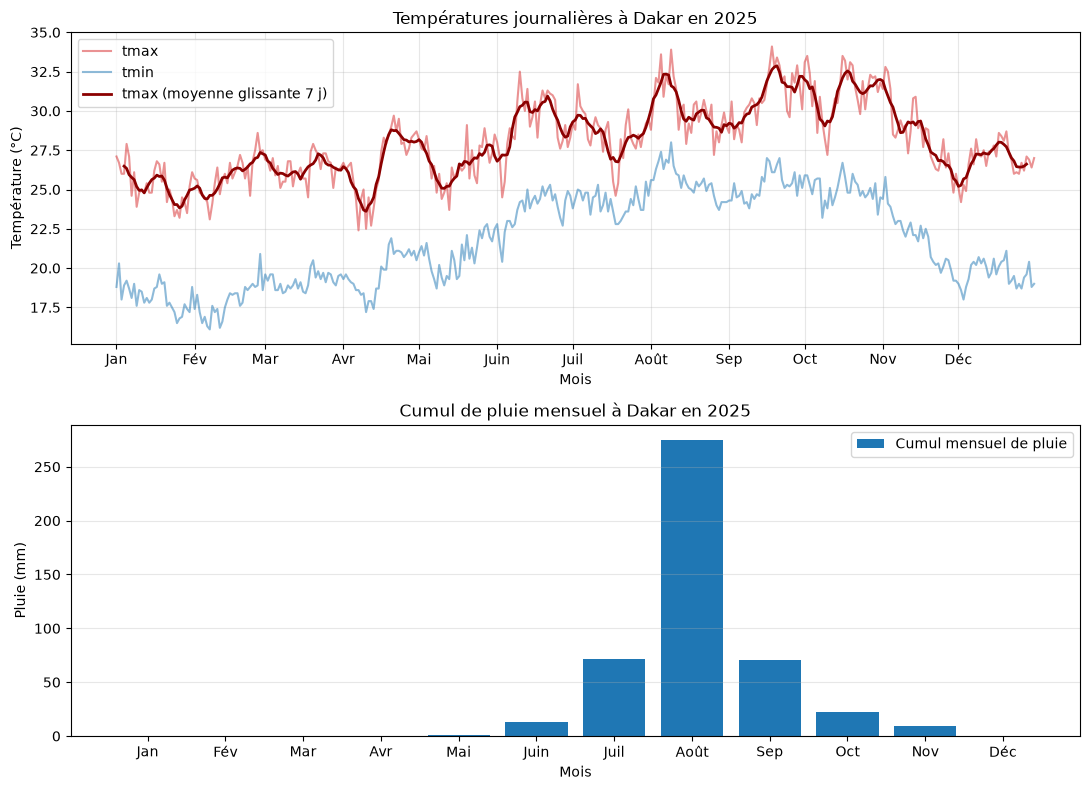

In [73]:
import matplotlib.pyplot as plt

jours = np.arange(365)
debuts_mois = np.cumsum(np.bincount(mois - 1)) - np.bincount(mois - 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8))

# Températures
ax1.plot(jours, tmax, label="tmax", color="tab:red", alpha=0.5)
ax1.plot(jours, tmin, label="tmin", color="tab:blue", alpha=0.5)
ax1.plot(jours[3:-3], moy_glissante, label="tmax (moyenne glissante 7 j)", color="darkred", linewidth=2)
ax1.set_title("Températures journalières à Dakar en 2025")
ax1.set_xlabel("Mois")
ax1.set_ylabel("Température (°C)")
ax1.set_xticks(debuts_mois)
ax1.set_xticklabels(NOMS_MOIS)
ax1.legend()
ax1.grid(alpha=0.3)

# Pluie mensuelle
ax2.bar(NOMS_MOIS, np.bincount(mois - 1, weights=pluie), color="tab:blue", label="Cumul mensuel de pluie")
ax2.set_title("Cumul de pluie mensuel à Dakar en 2025")
ax2.set_xlabel("Mois")
ax2.set_ylabel("Pluie (mm)")
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()